In [9]:
import pandas as pd
import numpy as np
import os
import matplotlib.pyplot as plt

data_path = '../02_Data/'
datasets = {
    'listings': pd.read_csv(os.path.join(data_path, 'listings.csv')),
    'calendar': pd.read_csv(os.path.join(data_path, 'calendar.csv')),
    'reviews': pd.read_csv(os.path.join(data_path, 'reviews.csv')),
    'neighbourhoods': pd.read_csv(os.path.join(data_path, 'neighbourhoods.csv'))
}

--- Invalid Value Checks ---
Listings price <= 0: 0
Listings minimum_nights <= 0: 0
Listings minimum_nights > 365: 3
Listings availability > 365: 0
Listings latitude out of range: 0
Listings longitude out of range: 0

--- Price Distribution (Listings) ---
count    13355.000000
mean       240.616470
std        339.474553
min          3.500000
25%         89.290000
50%        177.670000
75%        285.500000
90%        413.000000
95%        548.000000
99%       1815.000000
max      10542.220000
Name: price_num, dtype: float64

--- Minimum Nights ---
count    15292.000000
mean        14.058920
std         21.359699
min          1.000000
50%          2.000000
75%         31.000000
90%         32.000000
95%         32.000000
99%         45.000000
max        900.000000
Name: minimum_nights, dtype: float64

--- Availability 365 ---
count    15293.000000
mean       212.434970
std        119.050634
min          0.000000
25%        116.000000
50%        240.000000
75%        319.000000
95%      

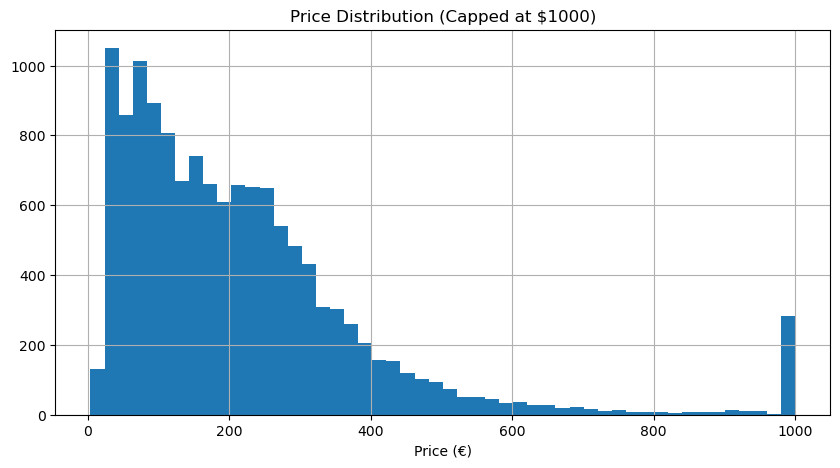

In [10]:
listings = datasets['listings'].copy()
calendar = datasets['calendar'].copy()

def clean_price(s):
    return pd.to_numeric(s.astype('str').str.replace(r'[\$,]','' , regex = True), errors = 'coerce')

listings['price_num'] = clean_price(listings['price'])
calendar['price_num'] = clean_price(listings['price'])

print("--- Invalid Value Checks ---")
print(f"Listings price <= 0: {(listings['price_num'] <= 0).sum()}")
print(f"Listings minimum_nights <= 0: {(listings['minimum_nights'] <= 0).sum()}")
print(f"Listings minimum_nights > 365: {(listings['minimum_nights'] > 365).sum()}")
print(f"Listings availability > 365: {(listings['availability_365'] > 365).sum()}")
print(f"Listings latitude out of range: {((listings['latitude'] < -90) | (listings['latitude'] > 90)).sum()}")
print(f"Listings longitude out of range: {((listings['longitude'] < -180) | (listings['longitude'] > 180)).sum()}")

# Task 9: Outliers — Price Distribution
print("\n--- Price Distribution (Listings) ---")
print(listings['price_num'].describe(percentiles=[.25, .5, .75, .90, .95, .99]))

# Task 9: Minimum Nights and Availability
print("\n--- Minimum Nights ---")
print(listings['minimum_nights'].describe(percentiles=[.5, .75, .90, .95, .99]))

print("\n--- Availability 365 ---")
print(listings['availability_365'].describe(percentiles=[.25, .5, .75, .95]))

listings['price_num'].dropna().clip(upper=1000).hist(bins=50, figsize=(10,5))
plt.title('Price Distribution (Capped at $1000)')
plt.xlabel('Price (€)')
plt.show()

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,host_url,host_profile_id,host_profile_url,host_name,host_since,hosts_time_as_user_years,hosts_time_as_user_months,hosts_time_as_host_years,hosts_time_as_host_months,host_location,host_about,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_thumbnail_url,host_picture_url,host_neighbourhood,host_listings_count,host_total_listings_count,host_verifications,host_has_profile_pic,host_identity_verified,neighbourhood,neighbourhood_cleansed,neighbourhood_group_cleansed,latitude,longitude,property_type,room_type,accommodates,bathrooms,bathrooms_text,bedrooms,beds,amenities,price,price_quote_checkin_date,price_quote_checkout_date,price_quote_total_price,price_quote_price_per_night,price_quote_raw,minimum_nights,maximum_nights,minimum_minimum_nights,maximum_minimum_nights,minimum_maximum_nights,maximum_maximum_nights,minimum_nights_avg_ntm,maximum_nights_avg_ntm,calendar_updated,has_availability,availability_30,availability_60,availability_90,availability_365,calendar_last_scraped,number_of_reviews,number_of_reviews_ltm,number_of_reviews_l30d,availability_eoy,number_of_reviews_ly,estimated_occupancy_l365d,estimated_revenue_l365d,first_review,last_review,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,18674,https://www.airbnb.com/rooms/18674,20260624162917,2026-06-25,city scrape,Huge flat for 8 people close to Sagrada Familia,110m2 apartment to rent in Barcelona. Located ...,NaN,https://a0.muscache.com/pictures/hosting/Hosti...,71615,https://www.airbnb.com/users/show/71615,1.462508e+18,https://www.airbnb.com/users/profile/146250835...,Maria Y Mireia Barcelona4Seasons,NaN,16.0,5.0,15.0,5.0,"Barcelona, Spain","We are Mireia and Maria, two multilingual entr...",NaN,NaN,NaN,f,NaN,https://a0.muscache.com/im/pictures/user/User/...,NaN,31.0,NaN,NaN,t,t,NaN,la Sagrada Família,Eixample,41.405560,2.17262,Entire rental unit,Entire home/apt,8,2.0,2 baths,3.0,5.0,"[""AC - split type ductless system"", ""Private p...",$409.00,2026-06-28,2026-06-29,409.00,409.00,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""...",1.0,999.0,1.0,4.0,999.0,999.0,2.2,999.0,NaN,t,15,22,52,123,2026-06-25,59,9,1,121,9,54,22086.0,2013-05-27,2026-05-28,4.41,4.47,4.59,4.66,4.64,4.83,4.38,Spain - National registration number<br />ESFC...,NaN,20,20,0,0,0.37
1,23197,https://www.airbnb.com/rooms/23197,20260624162917,2026-06-25,city scrape,CCIB Forum· Large Balcony · 5 min walk to CCIB,"Beautiful, spacious apartment with large balco...",NaN,https://a0.muscache.com/pictures/hosting/Hosti...,90417,https://www.airbnb.com/users/show/90417,1.462509e+18,https://www.airbnb.com/users/profile/146250935...,Marnie,NaN,16.0,3.0,15.0,5.0,"Catalonia, Spain","Hi there,\n\nI’m marnie, originally from Austr...",NaN,NaN,NaN,t,NaN,https://a0.muscache.com/im/pictures/user/44b56...,NaN,5.0,NaN,NaN,t,t,NaN,el Besòs i el Maresme,Sant Martí,41.412432,2.21975,Entire rental unit,Entire home/apt,5,2.0,2 baths,3.0,4.0,"[""AC - split type ductless system"", ""Private p...",$388.00,2026-06-26,2026-06-30,1552.00,388.00,"{""quote"": {""taxes"": null, ""currency"": ""EUR"", ""...",2.0,1125.0,2.0,7.0,1125.0,1125.0,3.5,1125.0,NaN,t,10,34,64,239,2026-06-25,99,11,1,159,11,66,25608.0,2011-03-15,2026-06-07,4.84,4.95,4.91,4.94,4.99,4.69,4.71,Spain - National registration number<br />ESFC...,NaN,1,1,0,0,0.53
2,34981,https://www.airbnb.com/rooms/34981,20260624162917,2026-06-25,city scrape,VIDRE HOME PLAZA REAL on LAS RAMBLAS,Spacious apartment for large families or group...,NaN,https://a0.muscache.com/pictures/c4d1723c-e479...,73163,https://www.airbnb.com/users/show